# Equipo 2 · Tendencia: ¿cuál ha sido la dirección general del precio?

**Curso:** Series temporales financieras  
**Fuente de datos:** Yahoo Finance mediante `yfinance`  
**Activo principal:** AAPL (Apple Inc.)  
**Período de trabajo:** enero de 2020 a diciembre de 2025

## Misión del equipo
**Pregunta central:** ¿Cómo podemos distinguir el movimiento general del precio de sus fluctuaciones diarias?

### Objetivos
- Explicar el concepto de tendencia.
- Comparar la serie observada con una referencia lineal sencilla.
- Reconocer que una tendencia histórica no garantiza el futuro.

### Consulta conceptual obligatoria
Antes de completar el análisis, consulten fuentes confiables y respondan con sus propias palabras:
- ¿Qué es tendencia en una serie temporal?
- ¿Cómo se diferencia de ruido o fluctuaciones de corto plazo?
- ¿Qué limitaciones tiene una línea de tendencia lineal?

**Importante:** este notebook es una plantilla de trabajo. Completen los espacios, expliquen el código con sus palabras y no se limiten a ejecutar las celdas. Citen las fuentes consultadas. Los resultados pueden variar según los datos disponibles al descargar.


## 1. Investigación previa
- Definición de tendencia: **[completar]**
- Diferencia entre tendencia y fluctuación diaria: **[completar]**
- Hipótesis sobre el comportamiento de AAPL en el período: **[completar antes de graficar]**

**Definición de tendencia:** Una tendencia es un patrón de cambio que muestra hacia donde va el interés de la gente o el comportamiento de un grupo antes de convertirse en una costumbre.

**Diferencia entre tendencia y fluctuación diaria:** La tendencia representa la evolución estructural y sostenida del precio a lo largo de meses o años; Mientras que, la fluctuación diaria o ruido corresponde a variaciones aleatorias de corto plazo causadas por noticias puntuales, ajustes intradía de liquidez o volatilidad habitual del mercado.

**Hipótesis sobre el comportamiento de AAPL en el periodo:** Se anticipa una tendecnia general alcista para APPL entre 2020 y 2025, sustentada en el crecimiento de sus ingresos por servicios y la solidez de su ecosistema tecnológico, aunque con etapas marcadas de corrección y volatilidad intermedia (especialmente durante los ciclos de subida de tasas de interés y ajustes del sector tecnológico).

In [ ]:
!pip -q install yfinance

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TICKER = "AAPL"
START = "2020-01-01"
END = "2026-01-01"

datos = yf.download(
    TICKER,
    start=START,
    end=END,
    auto_adjust=True,
    progress=False
)

# Algunas versiones de yfinance pueden devolver columnas MultiIndex.
if isinstance(datos.columns, pd.MultiIndex):
    datos.columns = datos.columns.get_level_values(0)

datos = datos.dropna(how="all")
datos.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2020-01-02,72.271538,72.331694,71.029915,71.282568,135480400
2020-01-03,71.568916,72.326882,71.345137,71.501542,146322800
2020-01-06,72.139191,72.177691,70.442792,70.693043,118387200
2020-01-07,71.799934,72.403897,71.580965,72.148835,108872000
2020-01-08,72.954903,73.255683,71.503938,71.503938,132079200


## 2. Crear una referencia de tendencia
La línea de regresión de este ejercicio es una aproximación descriptiva, no un modelo de predicción. Expliquen qué representa y por qué no sigue cada movimiento diario.

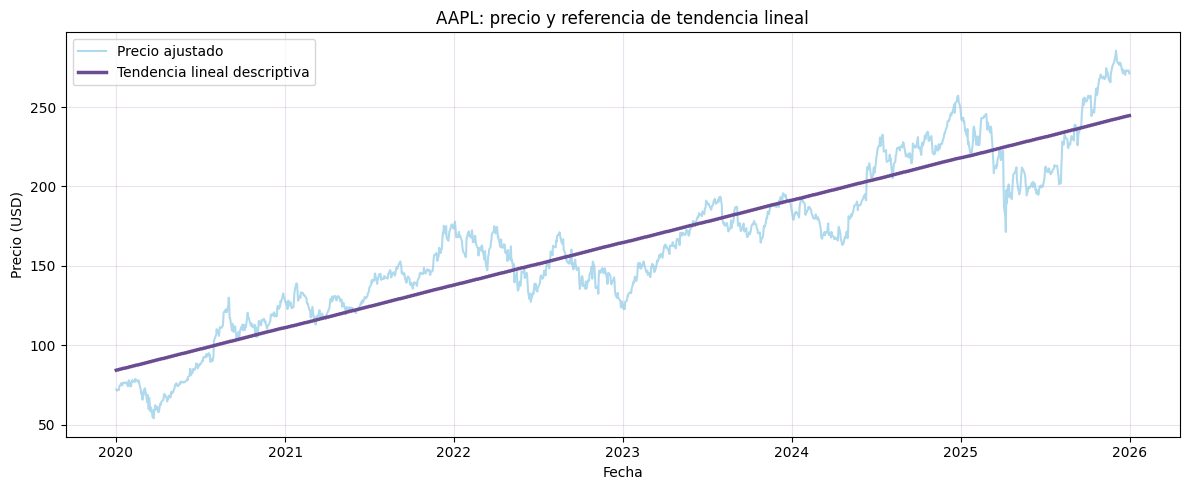

Pendiente estimada: 0.1063 USD por observación bursátil


In [ ]:
x = np.arange(len(datos))
y = datos["Close"].to_numpy(dtype=float)
pendiente, intercepto = np.polyfit(x, y, 1)
tendencia_lineal = pendiente * x + intercepto

plt.figure(figsize=(12, 5))

plt.plot(
    datos.index, datos["Close"],
    label="Precio ajustado",
    color="#8ECAE6",
    alpha=0.7
)

plt.plot(
    datos.index, tendencia_lineal,
    label="Tendencia lineal descriptiva",
    color="#6A4C93",
    linewidth=2.5
)

plt.title("AAPL: precio y referencia de tendencia lineal")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD)")
plt.legend()
plt.grid(True, color="#CDB4DB", alpha=0.4)
plt.tight_layout()
plt.show()

print(f"Pendiente estimada: {pendiente:.4f} USD por observación bursátil")

Muestra la evolución del precio ajustado de Apple a lo largo del tiempo frente a una línea de tendencia general. La pendiente estimada de 0.1063 USD por sesión bursátil confirma que Apple mantuvo una tendencia alcista constante y positiva a largo plazo durante el periodo analizado.

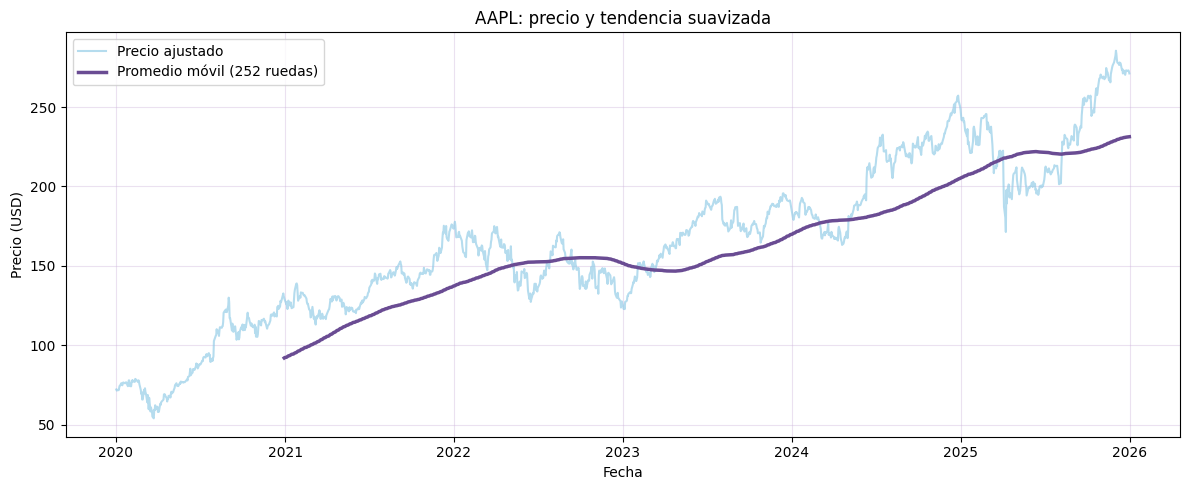

In [ ]:
# Promedio móvil de aproximadamente un año bursátil
datos["Promedio móvil 252 días"] = datos["Close"].rolling(window=252).mean()

plt.figure(figsize=(12, 5))

plt.plot(
    datos.index,
    datos["Close"],
    label="Precio ajustado",
    color="#8ECAE6",
    alpha=0.65
)

plt.plot(
    datos.index,
    datos["Promedio móvil 252 días"],
    label="Promedio móvil (252 ruedas)",
    color="#6A4C93",
    linewidth=2.5
)

plt.title("AAPL: precio y tendencia suavizada")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD)")
plt.legend()
plt.grid(True, color="#CDB4DB", alpha=0.4)
plt.tight_layout()
plt.show()


La media móvil de 252 días (equivalente a un año bursátil) amortigua la volatilidad cotidiana del activo. Esta curva permite aislar el comportamiento fundamental de Apple a mediano y largo plazo, visibilizando con precisión sus ciclos de expansión y las fases de ajuste del valor, libre del impacto de las fluctuaciones operativas de corto plazo.

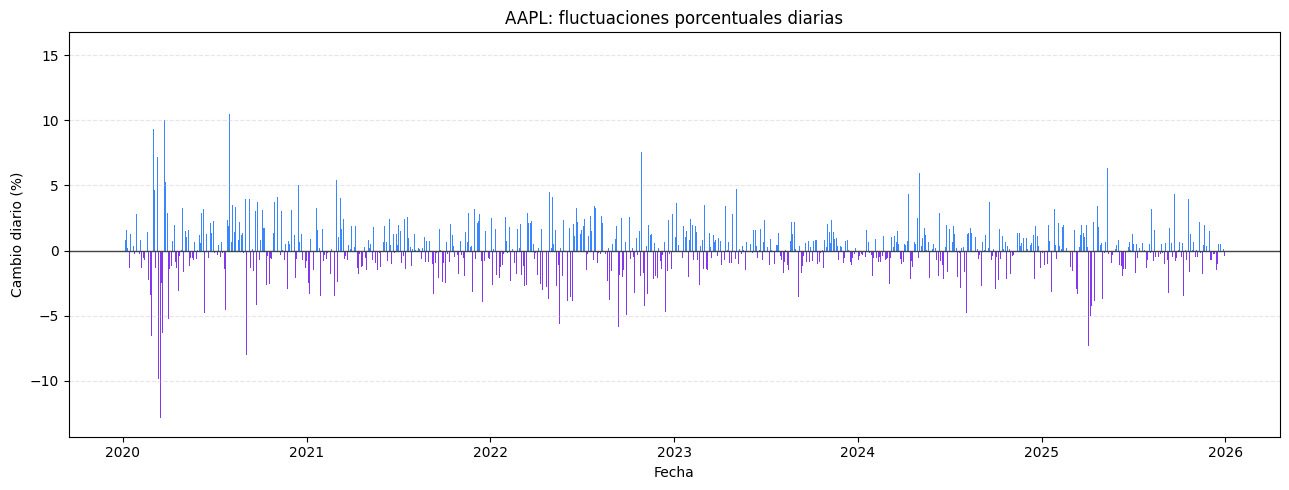

In [ ]:
# Cambio porcentual respecto al día bursátil anterior
cambio_diario = datos["Close"].pct_change() * 100

# Un color según el sentido del cambio
colores = ["#3A86FF" if cambio >= 0 else "#8338EC"
           for cambio in cambio_diario.fillna(0)]

plt.figure(figsize=(13, 5))
plt.bar(datos.index, cambio_diario, color=colores, width=1.0)

plt.axhline(0, color="#444444", linewidth=1)
plt.title("AAPL: fluctuaciones porcentuales diarias")
plt.xlabel("Fecha")
plt.ylabel("Cambio diario (%)")
plt.grid(axis="y", color="#CDB4DB", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Este gráfico refleja los cambios porcentuales diarios en el precio de Apple. Muestra que la mayoría de las variaciones cotidianas son pequeñas y se mantienen cercanas al 0\%. Sin embargo, se observan picos pronunciados en momentos específicos (como a inicios de 2020), los cuales representan días de alta volatilidad y reacciones fuertes del mercado ante eventos importantes.

## 3. Profundizar
Como comprobación, comparen el precio promedio del primer año disponible con el del último año disponible. No confundan esta comparación con una explicación causal.

In [ ]:
x = np.arange(len(datos))
y = datos["Close"].to_numpy(dtype=float)
pendiente, intercepto = np.polyfit(x, y, 1)
tendencia_lineal = pendiente * x + intercepto

anual = datos["Close"].resample("YE").mean().dropna()
print("Precio promedio por año:")
display(anual.to_frame("Precio promedio (USD)").round(2))
if len(anual) >= 2:
    print("Primer año:", anual.index[0].year, "| Último año:", anual.index[-1].year)
    print("Cambio entre promedios:", round(anual.iloc[-1] - anual.iloc[0], 2), "USD")




Precio promedio por año:


,Precio promedio (USD)
Date,
2020-12-31,92.27
2021-12-31,137.35
2022-12-31,151.67
2023-12-31,170.05
2024-12-31,205.28
2025-12-31,231.15


Primer año: 2020 | Último año: 2025
Cambio entre promedios: 138.88 USD


## 4. Interpretación
1. ¿La línea de tendencia resume bien todos los movimientos? ¿Por qué?
2. ¿En qué períodos el precio se aparta de la línea?
3. ¿Qué diferencia hay entre describir una tendencia pasada y pronosticar el futuro?
4. ¿Qué otra evidencia consultarían antes de tomar una decisión financiera?

**Conclusión del equipo:** [completar]

**1. ¿La línea de tendencia resume bien todos los movimientos? ¿Por qué?** No. Solo resume la dirección general (claramente alcista), pero no captura las caídas fuertes ni los periodos de aceleración, ya que simplifica la dinámica del precio a una línea recta rígida.

**2. ¿En qué períodos el precio se aparta de la línea?** Por debajo: A inicios de 2020 (choque por pandemia) y durante todo 2022 (mercado bajista por inflación y subida de tasas).

**3. ¿Qué diferencia hay entre describir una tendencia pasada y pronosticar el futuro?**
Describir mide matemáticamente lo que ya pasó; pronosticar proyecta hacia adelante bajo incertidumbre. En finanzas, el rendimiento histórico no garantiza retornos futuros.

**4. ¿Qué otra evidencia consultaría antes de tomar una decisión financiera?** Métricas de riesgo (volatilidad y caídas máximas), estados financieros de la empresa (ingresos, márgenes y deuda) y el entorno macroeconómico (tasas de interés e inflación).

**Conclusión del equipo:** AAPL presentó una marcada tendencia alcista entre 2020 y 2025 con pendiente positiva. Sin embargo, el precio se alejó frecuentemente de la recta durante shocks económicos (como en 2020 y 2022). La línea de tendencia es útil como referencia visual descriptiva, pero no sirve por sí sola para proyectar el precio ni tomar decisiones de inversión.

## 5. Fuentes y participación
Fuentes: **[enlaces]**. Aportes de integrantes: **[completar]**.

https://rpubs.com/JairoAyala/ST
https://www.geeksforgeeks.org/python/what-is-a-trend-in-time-series/
https://www.domo.com/learn/charts/trendline-chart
https://www.reddit.com/r/AskStatistics/comments/rs2mdg/is_prediction_and_forecast_have_the_same_meaning/?tl=es-es
